# 02. Red neuronal, ajuste de hiperparámetros y comparación final

Compara una red neuronal (Keras) con los tres modelos del notebook 01 usando
la misma evaluación: holdout de los últimos 12 meses y ventana móvil de 24 meses.

Los hiperparámetros se eligen con **validación cruzada de series de tiempo**
sobre los meses *anteriores* al holdout (dos pliegues de 12 meses). El holdout
no se usa para elegir nada.

In [1]:
import sys
from functools import partial

import matplotlib.pyplot as plt
import pandas as pd

sys.path.append("..")
from src.serie_mensual import cargar_serie_mensual
from src.modelos import (
    regresion_historico, regresion_ventana, random_forest,
    validar_series_temporales, tabla_comparativa,
)
from src.red_neuronal import red_neuronal

serie = cargar_serie_mensual("../data/totales_mensuales.csv")
print("Meses:", len(serie), "| último mes:", serie["fecha"].iloc[-1].date())

Meses: 140 | último mes: 2026-08-01


## 1. Ajuste de hiperparámetros

Familias y valores probados:
- **Regresión lineal:** tamaño de la ventana (12, 24, 36, 48 o 60 meses).
- **Random Forest:** `min_samples_leaf` (1, 2 o 5).
- **Red neuronal:** tamaño de las capas ocultas y número de épocas.

In [2]:
CANDIDATOS = {
    "Regresión lineal (ventana)": {
        f"ventana={v}": partial(regresion_ventana, ventana=v) for v in [12, 24, 36, 48, 60]
    },
    "Random Forest": {
        f"min_samples_leaf={l}": partial(random_forest, min_samples_leaf=l) for l in [1, 2, 5]
    },
    "Red neuronal": {
        f"unidades={u}, épocas={e}": partial(red_neuronal, unidades=u, epocas=e)
        for u in [(16, 8), (32, 16), (64, 32)]
        for e in [100, 300]
    },
}

filas = []
for familia, grid in CANDIDATOS.items():
    for config, predictor in grid.items():
        filas.append({
            "Familia": familia,
            "Configuración": config,
            "MAE validación (CV)": validar_series_temporales(serie, predictor),
        })
resultados_cv = pd.DataFrame(filas)
resultados_cv.round(0)

,Familia,Configuración,MAE validación (CV)
0,Regresión lineal (ventana),ventana=12,251661.0
1,Regresión lineal (ventana),ventana=24,119155.0
2,Regresión lineal (ventana),ventana=36,103971.0
3,Regresión lineal (ventana),ventana=48,65474.0
4,Regresión lineal (ventana),ventana=60,73136.0
5,Random Forest,min_samples_leaf=1,85914.0
6,Random Forest,min_samples_leaf=2,80804.0
7,Random Forest,min_samples_leaf=5,76287.0
8,Red neuronal,"unidades=(16, 8), épocas=100",120125.0
9,Red neuronal,"unidades=(16, 8), épocas=300",100668.0


In [3]:
# Mejor configuración por familia (menor MAE en validación cruzada)
elegidos = {}
for familia, grid in CANDIDATOS.items():
    sub = resultados_cv[resultados_cv["Familia"] == familia]
    mejor_config = sub.loc[sub["MAE validación (CV)"].idxmin(), "Configuración"]
    elegidos[familia] = (mejor_config, grid[mejor_config])
    print(f"{familia}: {mejor_config}")

Regresión lineal (ventana): ventana=48
Random Forest: min_samples_leaf=5
Red neuronal: unidades=(64, 32), épocas=300


## 2. Comparación final

Se muestran los modelos iniciales del notebook 01 (sin ajustar, para que la
comparación con el notebook anterior sea directa) junto a los modelos con
hiperparámetros elegidos por validación cruzada.

La evaluación final no cambió: holdout de 12 meses y ventana móvil de 24 meses,
con el modelo re-entrenado antes de cada mes.

In [4]:
PREDICTORES = {
    "Regresión lineal (histórico completo)": regresion_historico,
    "Regresión lineal (últimos 36 meses)": partial(regresion_ventana, ventana=36),
    "Random Forest": partial(random_forest, min_samples_leaf=2),
    f"Regresión lineal (ajustada: {elegidos['Regresión lineal (ventana)'][0]})": elegidos["Regresión lineal (ventana)"][1],
    f"Random Forest (ajustado: {elegidos['Random Forest'][0]})": elegidos["Random Forest"][1],
    f"Red neuronal ({elegidos['Red neuronal'][0]})": elegidos["Red neuronal"][1],
}

tabla_final = tabla_comparativa(serie, PREDICTORES)
tabla_final = tabla_final.rename(columns={
    "MAE holdout": "MAE (holdout 12 m)",
    "RMSE holdout": "RMSE (holdout 12 m)",
    "MAE móvil": "MAE (ventana móvil 24 m)",
    "RMSE móvil": "RMSE (ventana móvil 24 m)",
})
tabla_final

,MAE (holdout 12 m),RMSE (holdout 12 m),MAE (ventana móvil 24 m),RMSE (ventana móvil 24 m)
Regresión lineal (histórico completo),135961,141891,111779,117118
Regresión lineal (últimos 36 meses),61057,71372,47226,55248
Random Forest,104419,127186,84457,103948
Regresión lineal (ajustada: ventana=48),45976,55676,40057,47685
Random Forest (ajustado: min_samples_leaf=5),96231,114068,78246,95718
"Red neuronal (unidades=(64, 32), épocas=300)",47698,68663,58894,78022


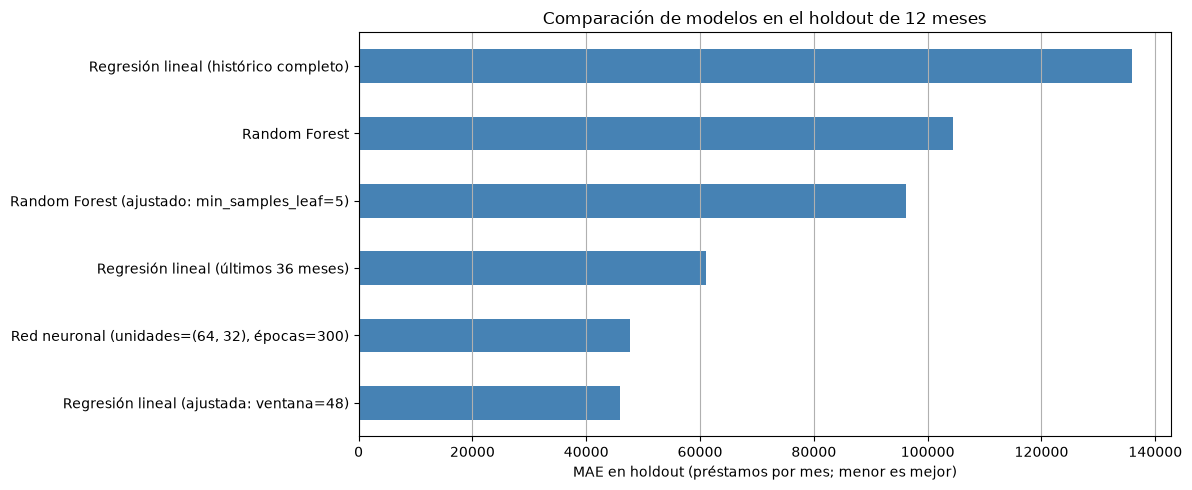

In [5]:
# Gráfica: MAE en holdout por modelo
fig, ax = plt.subplots(figsize=(12, 5))
tabla_final["MAE (holdout 12 m)"].sort_values().plot.barh(ax=ax, color="steelblue")
ax.set_xlabel("MAE en holdout (préstamos por mes; menor es mejor)")
ax.set_title("Comparación de modelos en el holdout de 12 meses")
ax.grid(True, axis="x")
plt.tight_layout()
plt.show()